# R9 · Géométrie du plan, vecteurs et trigonométrie — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r9_geometrie_vecteurs/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R9.1 à R9.10, R9.13, R9.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R9.16 | Le vecteur entre deux points et sa norme · `vector`, `norm` | 🔨 | ★ | 15 |
|  | R9.17 | Produit scalaire et angle · `dot`, `angle_between` | 🔨 | ★ | 20 |
|  | R9.18 | La droite qui passe par deux points, et les radians · `line_through`, `deg_to_rad` | 🔨 | ★ | 15 |
|  | R9.19 | Les mêmes calculs avec NumPy (`np.linalg.norm`, `@`) | 📦 | ★ | 15 |
| B | R9.20 | Prédire : multiplier ou décaler deux vecteurs change-t-il leur similarité cosinus ? | 🔮 | ★ | 10 |
|  | R9.21 | Dessiner des vecteurs, leur somme et un angle | 🎨 | ★★ | 20 |
|  | R9.22 | Le cercle trigonométrique : cos et sin d'un angle qui tourne | 🔬 | ★★ | 20 |
| C | R9.23 | Chasse à l'erreur : radians et degrés | 🐛 | ★ | 15 |
|  | R9.24 | Comparer deux flottants : `np.isclose` | 🛠️ | ★ | 10 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : distances, vecteurs, normes, droites, produit scalaire, radians, cosinus et sinus, angles, vecteurs de ℝ³ et ℝ⁴.
- Écrire les six fonctions de `mymath/plane.py` et les tester, puis refaire les calculs avec NumPy.
- Prédire l'effet d'un multiple sur la similarité cosinus, dessiner des vecteurs, explorer le cercle trigonométrique, chasser des confusions entre degrés et radians, comparer des flottants.

**Rappel express.** $AB = \sqrt{(x_B - x_A)^2 + (y_B - y_A)^2}$ ; $\overrightarrow{AB} = B - A$ ; $\lVert \vec{u} \rVert = \sqrt{x^2 + y^2}$ ; $\vec{u} \cdot \vec{v} = xx' + yy' = \lVert \vec{u} \rVert\,\lVert \vec{v} \rVert \cos\theta$. $ax + by + c = 0$ : $(-b ; a)$ directeur, $(a ; b)$ normal. $180° = \pi$ rad ; `math.cos` attend des radians.

## Partie 0 · Vérifier tes exercices papier (✏️ R9.1 à R9.10, 🔗 R9.13 et R9.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une valeur exacte entre guillemets, avec `sqrt` et `pi`, `"sqrt(5)/3"` ou `"2*pi/5"` ;
- des coordonnées, un vecteur ou une équation $[a, b, c]$ par une liste entre crochets, `[-1.25, 1]` ; vrai ou faux par `True` ou `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

import sympy as sp

**Ex R9.1 — Coordonnées et distance**

In [3]:
wbm.record("R9.1a", [(-3 + 6) / 2, (2 + 14) / 2], decimals=1, mistakes={"le milieu a pour coordonnées les moyennes de celles de A et B, pas la moitié des écarts": [4.5, 6], "la moyenne de deux nombres : leur somme divisée par 2": [3, 16]})
wbm.record("R9.1b", math.isqrt(9 ** 2 + 12 ** 2), mistakes={"la racine d'une somme n'est pas la somme des racines : élève les écarts au carré": 21, "AB est la racine carrée de la somme des carrés des écarts": 225})
wbm.record("R9.1c", math.sqrt(2 ** 2 + 1.5 ** 2), decimals=1, mistakes={"la racine d'une somme n'est pas la somme des racines : élève les écarts au carré": 3.5, "AC est la racine carrée de la somme des carrés des écarts": 6.25})
wbm.record("R9.1d", math.sqrt(7 ** 2 + 13.5 ** 2), decimals=2, mistakes={"la racine d'une somme n'est pas la somme des racines : élève les écarts au carré": 20.5, "BC est la racine carrée de la somme des carrés des écarts": 231.25})
wbm.record("R9.1e", True, mistakes={"compare BC² à AB² + AC² (réciproque de Pythagore), avec les longueurs au carré": False})
wbm.record("R9.1f", math.sqrt(6 ** 2 + 14 ** 2), decimals=2, mistakes={"la racine d'une somme n'est pas la somme des racines : élève les coordonnées au carré": 20})
wbm.record("R9.1g", Fraction(219, 18), kind="fraction", simplified=True, mistakes={"un point de l'axe des abscisses a une ordonnée nulle, mais celles de A et B comptent dans MA et MB": "3/2"})
wbm.record("R9.1h", [2 * 6 - (-3), 2 * 14 - 2], mistakes={"c'est le milieu de [AB] ; A' est de l'autre côté de B, à la même distance": [1.5, 8], "c'est le vecteur AB ; A' est le point d'arrivée quand on part de B": [9, 12]})

WBM_ANSWER {"decimals": 1, "element_hashes": ["496939d63800e5de72def6398601ee2c66b19acddd59b76bd1e9cf38a1b0992b", "199aaab020d48c5134653f8f784ab126a63bef7d7b44a04dfe0220ea222b2fc7"], "hash": "ef9b31962138818a9ab1f5f9b6fa8a165e760303b32d7f0064cc8aa731750106", "id": "R9.1a", "kind": "array", "mistakes": {"d6a657b1103a3b5b1647d263830121c7ac6e0073dac437ba60d0865634535ec1": "la moyenne de deux nombres : leur somme divisée par 2", "e18e700c904491a60e293c02fa33aa8a4b0897add59223302f71828ff59c0e2b": "le milieu a pour coordonnées les moyennes de celles de A et B, pas la moitié des écarts"}, "shape": [2]}
📝 Ex R9.1a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"hash": "eb1986030d3cc369c2c5ec42b3dbe472f2f22bab16f769a4b875851b13b21ba6", "id": "R9.1b", "kind": "int", "magnitude": 1, "mistakes": {"f1731cb4bbab58b6285c78ddc12e18c46846cc9bcef8f7e18c95ca9daf586650": "la racine d'une somme n'est pas la somme des racines : élève les écarts au carré", "f565ad64b73defe04af20199432ad57e117fa3e1f97

**Ex R9.2 — Vecteurs : somme, différence, produit par un nombre**

In [4]:
wbm.record("R9.2a", [4 - 2, -1 + 3])
wbm.record("R9.2b", [4 + 2, -1 - 3], mistakes={"soustraire, c'est ajouter l'opposé, coordonnée par coordonnée": [2, 2]})
wbm.record("R9.2c", [3 * 4 - 2 * (-2), 3 * (-1) - 2 * 3], mistakes={"le produit de deux nombres négatifs est positif": [8, -9]})
wbm.record("R9.2d", [-3 - 1, 5 - 2], mistakes={"les coordonnées d'un vecteur : arrivée moins départ": [4, -3]})
wbm.record("R9.2e", [1 + 4, 2 - 1], mistakes={"AC = u : on part de A et l'on se déplace de u, donc C = A + u": [-3, 3]})
wbm.record("R9.2f", [5 - (-4), 1 - 3], mistakes={"ABCD dans cet ordre : AB = DC, pas AB = CD": [1, 4], "ABCD dans cet ordre : c'est AB = DC qui donne D, pas AD = BC": [9, 4]})
wbm.record("R9.2g", True, mistakes={"deux vecteurs sont colinéaires quand leurs coordonnées sont proportionnelles : calcule xy' − x'y": False})
wbm.record("R9.2h", 5 / -2, decimals=1, mistakes={"le signe : la première coordonnée de v est négative": 2.5})

WBM_ANSWER {"decimals": 0, "element_hashes": ["e3248e108aa9fb8a7dbd9958711468a7a8dcc338fd00245ec88d39a6a2fcb397", "1b75908a63a27da545035c42b89fdf610c7410e930fdcc0ac3de23a819c4594b"], "hash": "cd4ca481f8614d47eab22fc5101bb0c11e8746eb038080bda97237d16b35778c", "id": "R9.2a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex R9.2a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["8216782622210f2141b6b395ae99165fae424502d9759022af4b1a62d996f198", "56a7d39e097169b4746f73994eb83c4883b9e1db14517d594def983370bbc4d7"], "hash": "d7775134e0de8217c9090d9c602fc1e3194ec634da437155a33865c336c4e27b", "id": "R9.2b", "integer": true, "kind": "array", "mistakes": {"6f44476fd029c025a4e4fe085a8739872af6deb39dde670d92045343dd21ca35": "soustraire, c'est ajouter l'opposé, coordonnée par coordonnée"}, "shape": [2]}
📝 Ex R9.2b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["6924a980f245839517ad11f21e7e0a373379e11b5113e1e7809aad

**Ex R9.3 — Normes (euclidienne, avec un aperçu de L1 et L∞) et vecteurs unitaires**

In [5]:
wbm.record("R9.3a", math.sqrt(34), decimals=2, mistakes={"le carré d'un nombre négatif est positif : (−3)² = 9": 4, "la norme est la racine de la somme des carrés": 34})
wbm.record("R9.3b", [-3, 3], mistakes={"t² = 9 a deux solutions, opposées": [3], "‖(t ; 2)‖² = t² + 4 : la norme vaut √13, donc son carré vaut 13": [-1, 1]})
wbm.record("R9.3c", 2 * math.sqrt(34), decimals=2, mistakes={"‖ku‖ = |k| ‖u‖ : une norme n'est jamais négative": -11.66, "multiplier un vecteur par k multiplie sa norme par |k|, pas par k²": 23.32})
wbm.record("R9.3d", [1 / math.sqrt(5), -2 / math.sqrt(5)], decimals=2, mistakes={"divise par la norme euclidienne, la racine de la somme des carrés": [1 / 3, -2 / 3], "même sens : on divise par un nombre positif, la norme": [-0.45, 0.89]})
wbm.record("R9.3e", math.sqrt(3 ** 2 + 12 ** 2), decimals=1, mistakes={"la norme d'une somme n'est pas la somme des normes : additionne d'abord les vecteurs": 22.8})
wbm.record("R9.3f", 8, mistakes={"la norme L1 additionne les valeurs absolues": 2})
wbm.record("R9.3g", 5, mistakes={"la norme L∞ est la plus grande valeur absolue": {3, -3}})
wbm.record("R9.3h", [3 * 5 / math.sqrt(34), 3 * (-3) / math.sqrt(34)], decimals=2, mistakes={"3u a pour norme 3 ‖u‖, pas 3 : rends d'abord u unitaire": [15, -9], "c'est le vecteur unitaire, de norme 1 ; la norme demandée est 3": [0.86, -0.51]})

WBM_ANSWER {"coarse_any": {"0": ["f16a4aa26d84e543b78d08cf3ffcbf8be43a8acb85f9f743d6c478be3575960e"]}, "decimals": 2, "hash": "bb20997160d11070b3b86044c0cbe5c2186eccef5c1a2bf456972d9994d4363b", "hash_coarse": "6828164a967eab92d40bbd5c9b773badc3a8f97b33c66421c83e95cb02660e8e", "id": "R9.3a", "kind": "float", "magnitude": 0, "mistakes": {"69f346c82978a562f0c81fc5eccc2551acfdd43a92bdece695b475eb19a49e2e": "le carré d'un nombre négatif est positif : (−3)² = 9", "b8a6f29e5ede770515f10cfca6a6b7af324df46e8c0a15e600ad71b7b25e49d1": "la norme est la racine de la somme des carrés"}, "sign": 1}
📝 Ex R9.3a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 0, "element_hashes": ["92aca66aef536e5955ea11b3751a45fd768c0c667f65d0017a86f05825694e71", "fc39d4351505bff83cec9d38300710ca30dec712846facd92fd000dde2952583"], "hash": "78f1efadaca8fd53aeff53336052fce815ec423b44aff91e6039c3dc47908d8d", "id": "R9.3b", "integer": true, "kind": "array", "mistakes": {"8f5b73512132f87ecf72835554d86056

**Ex R9.4 — Équations de droites**

In [6]:
wbm.record("R9.4a", (-1 - 5) / (2 - (-2)), decimals=1, mistakes={"la pente est l'écart des ordonnées divisé par l'écart des abscisses": -0.67, "le point mis en premier en haut doit être en premier en bas": 1.5})
wbm.record("R9.4b", round(5 - (-1.5) * (-2)), mistakes={"p = y_A − m x_A, avec les signes de m et de x_A": 8})
wbm.record("R9.4c", [2, -3], mistakes={"un vecteur directeur (1 ; m) : la seconde coordonnée se lit avec le signe de la pente": [2, 3]})
wbm.record("R9.4d", [3, 2, -4], mistakes={"vérifie ton équation avec les coordonnées de A et de B : chacune doit donner 0": [3, -2, -4], "tout passer du même côté change le signe de p": [3, 2, 4]})
wbm.record("R9.4e", Fraction(4, 6), kind="fraction", simplified=True, mistakes={"isole y : 6y = 4x + 9": "-2/3", "pour ax + by + c = 0, la pente vaut −a/b, pas −b/a": "3/2"})
wbm.record("R9.4f", round(1 - (-1.5) * 2), mistakes={"une parallèle a la même pente, pas la même ordonnée à l'origine : elle passe par C": 2, "p = y_C − m x_C, avec les signes de m et de x_C": -2})
wbm.record("R9.4g", [0.8, 0.8], decimals=1, mistakes={"le point commun vérifie les deux équations : remplace y par x dans celle de (AB)": [2, 2]})
wbm.record("R9.4h", [1, 0, 2], mistakes={"la droite verticale x = −2 s'écrit x + 2 = 0": [1, 0, -2], "les deux points ont la même abscisse : la droite est verticale, son équation ne contient pas y": [0, 1, 2]})

WBM_ANSWER {"decimals": 1, "hash": "260bed451995874365e196d25384caa41f4bf4aca8832690a1d611579c3b1183", "hash_coarse": "767e9080c11eb6713306f6f11aa989c3048d2d96f3fe34c04688d78f32ac0916", "id": "R9.4a", "kind": "float", "magnitude": 0, "mistakes": {"510c05cf1dff557cebcc7b321ff6450c17619fb2b8036b80d6eb301516137b78": "le point mis en premier en haut doit être en premier en bas", "986963d928c674fabffdf0943f0f2ebb03ecc575ef3f96da3756d1a360020062": "la pente est l'écart des ordonnées divisé par l'écart des abscisses"}, "sign": -1}
📝 Ex R9.4a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"hash": "993764a1497f5b664c8b7d5b2987019e4446416f92944551e10dbeed1a95cdab", "id": "R9.4b", "kind": "int", "magnitude": 0, "mistakes": {"fc877dadddb9bde2e296fa014e31823340b38c497dfc91c80ea3b58663420551": "p = y_A − m x_A, avec les signes de m et de x_A"}, "sign": 1}
📝 Ex R9.4b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a46f21f2242fa0674a81bf4fc21487500461f8d4df1f48694a3

**Ex R9.5 — Le produit scalaire en coordonnées**

In [7]:
wbm.record("R9.5a", 2 * (-3) + 5 * 1, mistakes={"multiplie les coordonnées de même rang, puis additionne les deux produits": -11})
wbm.record("R9.5b", 2 * 6 + 5 * 3)
wbm.record("R9.5c", -3 * 6 + 1 * 3)
wbm.record("R9.5d", float(2 * 2 + 5 * 5), decimals=2, mistakes={"u·u = ‖u‖², sans racine carrée": 5.39})
wbm.record("R9.5e", (2 - 3) * 6 + (5 + 1) * 3, mistakes={"additionne d'abord u et v, coordonnée par coordonnée": 27})
wbm.record("R9.5f", 2 * (-3) * (2 * (-3) + 5 * 1), mistakes={"(2u)·(−3v) = 2 × (−3) × (u·v), avec le signe": -6})
wbm.record("R9.5g", -5 * 4 // 2, mistakes={"orthogonaux : 2t + 5 × 4 = 0, puis isole t avec son signe": 10})
wbm.record("R9.5h", True, mistakes={"le signe du produit scalaire donne la nature de l'angle : positif, aigu": False})

WBM_ANSWER {"hash": "c16b6d00aef22c23ebff0a5f44d7cba7572cd253230f1b332b7052cf00909308", "id": "R9.5a", "kind": "int", "magnitude": 0, "mistakes": {"e3b053a4e0c4983a4b38400ebb46168d07023dec01a6ac252909f83415e8d6b2": "multiplie les coordonnées de même rang, puis additionne les deux produits"}, "sign": -1}
📝 Ex R9.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "afe0b587bad66e642cf9c8fe435f998c447e1e89299987c668b4d4182a690128", "id": "R9.5b", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex R9.5b : réponse enregistrée (int).
WBM_ANSWER {"hash": "e847f4b3e8144a940034eadc183e18e32b1219394a17049e9af7a400d7558236", "id": "R9.5c", "kind": "int", "magnitude": 1, "sign": -1}
📝 Ex R9.5c : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["709d0d2e912b997244e7e3e9df33787300136ae3d16aaf7e9696fca524d54539"]}, "decimals": 2, "hash": "84dd7e2c0bb5962b6565bdae2c42321a035ca043225381e4d3e20aa6a382930a", "hash_coarse": "792c2ca628694afd07a411ac5f28d585d3f9c0829da8013a5e2766611d13780f", "id": "

**Ex R9.6 — Orthogonalité et projections simples**

In [8]:
wbm.record("R9.6a", True, mistakes={"calcule le produit scalaire : nul, ils sont orthogonaux": False})
wbm.record("R9.6b", [4, 10], mistakes={"écris 5 × 4 + (−2) × y = 0, puis isole y avec son signe": [4, -10]})
wbm.record("R9.6c", -2 / 5, decimals=1, mistakes={"3k + 2(k + 1) = 0 : développe 2(k + 1), puis isole k avec son signe": 0.4})
wbm.record("R9.6d", True, mistakes={"l'angle en A est celui de AB et AC : calcule leur produit scalaire": False})
wbm.record("R9.6e", 20 / math.sqrt(10), decimals=2, mistakes={"la longueur de la projection est u·v divisé par ‖u‖": 20, "c'est le coefficient k de p = k u ; la longueur se divise par ‖u‖, pas par ‖u‖²": 2})
wbm.record("R9.6f", [6, 2], mistakes={"p = (u·v / ‖u‖²) u : divise par le carré de la norme": [60, 20]})
wbm.record("R9.6g", [-1, 3], mistakes={"le reste est v − p, pas p − v": [1, -3]})
wbm.record("R9.6h", True, mistakes={"compare les vecteurs directeurs (1 ; m) des deux droites par leur produit scalaire": False})

WBM_ANSWER {"hash": "eede7691ba609fd6123ecbc155c11dd01f0e9ee0037cdbbbc96adf57ba422d29", "id": "R9.6a", "kind": "bool", "mistakes": {"8d7ec1e273ce1eb97cbcb2c439cd36ad5c965c0411003206b3da3a1139505ba0": "calcule le produit scalaire : nul, ils sont orthogonaux"}}
📝 Ex R9.6a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 0, "element_hashes": ["41acdb62cbded3774293d975c165460a5d5a6131ef29498bb3caeb3cf696f740", "361873e24c17b34eb942c88b6ecd1b30a1b7cc471ef65a33417f778c00806aa0"], "hash": "11f26acec6a1c7b9ca4c9ca6cf08b3e67082e1cb33baf39acd56658adffa6530", "id": "R9.6b", "integer": true, "kind": "array", "mistakes": {"22656775a22b504d1a59118d1e927afac5ffbcf281c003fccd7a4361fa2749eb": "écris 5 × 4 + (−2) × y = 0, puis isole y avec son signe"}, "shape": [2]}
📝 Ex R9.6b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 1, "hash": "4629291c909338dae8beeca663b057d2689d228a96dae5b17e5b656236d7a2a0", "hash_coarse": "4cfea99a1ec8a44878864513965bfc5887742807c3005afadfe4e2ddb0bb60b

**Ex R9.7 — Degrés et radians, cosinus et sinus remarquables**

In [9]:
wbm.record("R9.7a", 7 * sp.pi / 12, kind="exact", angle=True, mistakes={"θ en radians = θ en degrés × π/180 : 180° donnent π": "12*pi/7"})
wbm.record("R9.7b", 7 * 180 // 6)
wbm.record("R9.7c", 180 / math.pi, decimals=1, mistakes={"de radians en degrés, on multiplie par 180/π (π radians donnent 180°)": 0.0175})
wbm.record("R9.7d", sp.cos(5 * sp.pi / 6), kind="exact", mistakes={"5π/6 = π − π/6 : c'est le cosinus de π/6 (au signe près) qui compte, pas celui de π/3": "-1/2"})
wbm.record("R9.7e", sp.sin(7 * sp.pi / 4), kind="exact")
wbm.record("R9.7f", sp.cos(3 * sp.pi / 2), kind="exact", mistakes={"3π/2 est en bas du cercle : regarde son abscisse": "-1"})
wbm.record("R9.7g", sp.sin(11 * sp.pi / 6), kind="exact", mistakes={"11π/6 = 2π − π/6 : le sinus de π/6 vaut 1/2, celui de π/3 vaut √3/2": "-sqrt(3)/2"})
wbm.record("R9.7h", sp.sin(5 * sp.pi / 2), kind="exact", mistakes={"5π/2 = π/2 + 2π : un tour complet ramène au même point": "-1"})

WBM_ANSWER {"angle": true, "hash": "c763a344020153c844b8db779199c6fb025208d950a4ab70fc6b24a4516479d0", "id": "R9.7a", "kind": "exact", "mistakes": {"477fbbaae086f8512ffa1027a7e378af399d8be40b156846c309dee198fc2672": "θ en radians = θ en degrés × π/180 : 180° donnent π"}, "rounded": {"1": "25d363a82bbcd173a57409ebfc0b97b6d1dffd92854da0587aaf12b7ccd95cc1", "2": "3e26f22f45e3917c0c0fe9f83b9515512753690caf17894ed1cae7bc446cf01c", "3": "e4669935371ec4ad5e9b940acb48466f35b84c6fc73683e9ffb29cf4d0c6541f", "4": "4087f2fc3962765d93188c213606259b5c0c66a7b56c170179186154b8ec8257", "5": "bfc3b4922b485c94704f7145c17c19147531d6e63e1b58cf092fd77ff3eabe28", "6": "007506f8ce8f8eba7277150d155a92aee291e81338742164230fefa214c43fe9", "7": "6689e033efe21044c9b82b8e1619bc295f8b18cd409fb63ad2846a0d8dfb8deb", "8": "833dd683bed3be468211a88231583cf6596e60da635615b5e4d746e84fef4cd8"}}
📝 Ex R9.7a : réponse enregistrée (exact).
WBM_ANSWER {"hash": "5f3e7d2a5f9979d5d086d9ff3e50db67050d0d165b47e201690ad84b6e1ff1ef", "

**Ex R9.8 — Les courbes de cos et de sin : période, symétries, et arccos sur [0, π]**

In [10]:
wbm.record("R9.8a", 2 * sp.pi / 3, kind="exact", angle=True, mistakes={"multiplier l'angle par 3 fait tourner 3 fois plus vite : la période est divisée par 3": "6*pi", "la période dépend du facteur 3 devant t": "2*pi"})
wbm.record("R9.8b", [90, 270], mistakes={"le cosinus s'annule deux fois par tour, en haut et en bas du cercle": [90], "ce sont les zéros du sinus ; le cosinus est l'abscisse du point": [0, 180]})
wbm.record("R9.8c", 2, mistakes={"deux points du cercle ont la même ordonnée 0,3 : un de chaque côté de l'axe vertical": 1})
wbm.record("R9.8d", sp.pi / 4, kind="exact", angle=True)
wbm.record("R9.8e", sp.pi / 3, kind="exact", angle=True, mistakes={"arccos rend toujours un angle de [0 ; π], qui a le même cosinus": "5*pi/3"})
wbm.record("R9.8f", True, mistakes={"π − x est le symétrique de x par rapport à l'axe vertical : même ordonnée": False})
wbm.record("R9.8g", 3 + 2, mistakes={"cos x vaut au plus 1, et 2 cos x au plus 2": 3})
wbm.record("R9.8h", 2, mistakes={"règle de la chaîne : la dérivée de sin(2x) est 2 cos(2x)": 1})

WBM_ANSWER {"angle": true, "hash": "5650fe0100a47fd256a495f9de6e281f788ffdb7626b7422b719c7277b747748", "id": "R9.8a", "kind": "exact", "mistakes": {"72cd59067ccb14361219cbfd8211b32319ecba9b67b450baaf8e07d4059e7b21": "multiplier l'angle par 3 fait tourner 3 fois plus vite : la période est divisée par 3", "e625d7e5e092fe69fd69886e3abecd6b4b028240319de17aba688a68f4299505": "la période dépend du facteur 3 devant t"}, "rounded": {"1": "c05f90fdfe2d69238f8cf535701d4a839b667b65d4a33efc56c1c5baa73f8c1a", "2": "35181beddcbab823d3e63cba020ee152eb50be5ac7729537e2444e957763e179", "3": "829a780490f0d3f3a522ce3d9b0d93df7917662ca239a2c291edfeaa760c2b62", "4": "bad3acb99d91211610532b502c401a1bce1b039bc1c71e030a73dbcc9cdfa454", "5": "90bcad9658a8f2d367761a05f3c3d5453ab13896b0a71c350d332888cf684694", "6": "d52894f08b50cebf0c9c36289b1a911123b83e6aa7715c9d1f592baf8d60632d", "7": "e72d23cd55a7e30ac90692cd7a86976fa1d46df9f2e1a23a993031c95112f6e7", "8": "cf6ee51acfa6dff64ca30034bea021e977d16da7f1a02d09102d36

**Ex R9.9 — L'angle entre deux vecteurs**

In [11]:
wbm.record("R9.9a", 2 / math.sqrt(85), decimals=4, mistakes={"divise le produit scalaire par le produit des normes": 2, "les normes sont des racines carrées : ne multiplie pas les sommes de carrés entre elles": 2 / 85})
wbm.record("R9.9b", math.degrees(math.acos(2 / math.sqrt(85))), decimals=1, mistakes={"math.acos rend des radians : convertis en degrés": 1.4})
wbm.record("R9.9c", 135, mistakes={"le produit scalaire est négatif : l'angle est obtus": 45})
wbm.record("R9.9d", 150, mistakes={"le produit scalaire est négatif : l'angle est obtus": 30})
wbm.record("R9.9e", sp.pi, kind="exact", angle=True, mistakes={"deux vecteurs de sens contraires font un angle plat, pas nul": "0"})
wbm.record("R9.9f", math.degrees(math.acos(4 / (4 * math.sqrt(10)))), decimals=1, mistakes={"math.acos rend des radians : convertis en degrés": 1.2})
wbm.record("R9.9g", 45, mistakes={"l'angle en B est celui des vecteurs BA et BC, qui partent de B": 135})
wbm.record("R9.9h", math.degrees(math.acos(6 / math.sqrt(180))), decimals=1, mistakes={"l'angle en C est celui de CA et CB, qui partent de C ; la somme des angles d'un triangle vaut 180°": 116.6})

WBM_ANSWER {"coarse_any": {"1": ["1601d99509d36a73234087eac678c583d0d54b644ed7e72714b577040b1a8629"]}, "coarser": {"2": ["85f9d8f8cec33150cb51a61c32dd8716378a18538fc82e9733272473d53d04e9"]}, "decimals": 4, "hash": "c50f4dd5cd1bc6e519b9e14c4e4de8c08dd87245acf2ca1baf539b4270a2b16c", "hash_coarse": "0876fea79fff55c73574e1111ac62b4bc761619d4e4e64555c70e9e78886425c", "id": "R9.9a", "kind": "float", "magnitude": -1, "mistakes": {"7abdf78c2ce4e58b58f97548d599cc2c534fb542122bb9601d693c46936c6a0a": "divise le produit scalaire par le produit des normes", "ea8ce11bb759e32d9d41a8e9ee987affc72d8ab76e6cf5aba89fcf360cf0cc01": "les normes sont des racines carrées : ne multiplie pas les sommes de carrés entre elles"}, "sign": 1}
📝 Ex R9.9a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 1, "hash": "940b59fd8ecd9a9ce27c03d0d2da6d5f766a9de431029c1afda29fce9ce1615d", "hash_coarse": "d1a575e55d2cc12f29beee3f9469b9f97c681a75e71b91adb92d294a4a5ea717", "id": "R9.9b", "kind": "float", "magn

**Ex R9.10 — Distances et produits scalaires dans ℝ³ et ℝ⁴**

In [12]:
wbm.record("R9.10a", math.isqrt(1 + 16 + 64), mistakes={"la norme est la racine de la somme des carrés des trois coordonnées": {13, 81}})
wbm.record("R9.10b", 1 * 3 + 4 * (-2) + 8 * 1)
wbm.record("R9.10c", math.isqrt(2 ** 2 + 6 ** 2 + 3 ** 2), mistakes={"la racine d'une somme n'est pas la somme des racines : élève les écarts au carré": 11})
wbm.record("R9.10d", 3 / (9 * math.sqrt(14)), decimals=3, mistakes={"divise par le produit des deux normes, pas par une seule": {0.333, 0.802}})
wbm.record("R9.10e", True, mistakes={"calcule le produit scalaire des quatre coordonnées": False})
wbm.record("R9.10f", math.sqrt(27), decimals=2, mistakes={"la norme est la racine de la somme des carrés": 27, "c'est la norme L1 ; ‖y‖ est la norme euclidienne": 9})
wbm.record("R9.10g", 3 + 1 + 1 + 4, mistakes={"la norme L1 additionne les valeurs absolues : |−1| = 1": 7})
wbm.record("R9.10h", Fraction(4, 3), kind="fraction", simplified=True, mistakes={"2 + 3t − 2 − 4 = 0 : isole t avec son signe": "-4/3"})

WBM_ANSWER {"hash": "fea76aa20587e4c2a3148d702708978777ac9c811aea2096d34bd90c42b545e0", "id": "R9.10a", "kind": "int", "magnitude": 0, "mistakes": {"12642d06de31d645540022919a2747de9efaec6a4642688a13f2e7eba8685614": "la norme est la racine de la somme des carrés des trois coordonnées", "a0638968310f5fcd3a710692edc8974e720cd0cc38f3ec854a6097ad956e8a05": "la norme est la racine de la somme des carrés des trois coordonnées"}, "sign": 1}
📝 Ex R9.10a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2d09136584d1d6e50a3f019c7cde7572284f86612cb15118ebc3617ae3a8763d", "id": "R9.10b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex R9.10b : réponse enregistrée (int).
WBM_ANSWER {"hash": "33f327019f9b99c8f8d06d20e57f52bf941e18a9538ecdbc1839bcaf6074c5a2", "id": "R9.10c", "kind": "int", "magnitude": 0, "mistakes": {"fe0d02fee820b46206bcf5318568c29a41315ce79ec862976422c3b7f805c5e2": "la racine d'une somme n'est pas la somme des racines : élève les écarts au carré"}, "sign": 1}
📝 Ex R9.10c : réponse 

**Ex R9.13 — Deux recettes, deux vecteurs d'ingrédients : la similarité cosinus**

In [13]:
wbm.record("R9.13a", 5 * 5 + 1 * 5 + 1 * 5 + 10 * 0)
wbm.record("R9.13b", math.sqrt(25 + 1 + 1 + 100), decimals=2, mistakes={"la norme est la racine de la somme des carrés": 127})
wbm.record("R9.13c", math.sqrt(75), decimals=2, mistakes={"la norme est la racine de la somme des carrés": 75})
wbm.record("R9.13d", 35 / (math.sqrt(127) * math.sqrt(75)), decimals=3, mistakes={"la similarité cosinus divise le produit scalaire par le produit des normes": 35})
wbm.record("R9.13e", 55 / (math.sqrt(75) * 7), decimals=3)
wbm.record("R9.13f", 102 / 127, decimals=3)
wbm.record("R9.13g", "q", mistakes={"compare les similarités cosinus, pas les produits scalaires": "p", "on compare les sablés aux trois autres recettes : la réponse est c, q ou p": "s"})
wbm.record("R9.13h", math.degrees(math.acos(35 / (math.sqrt(127) * math.sqrt(75)))), decimals=1, mistakes={"math.acos rend des radians : convertis en degrés": 1.2})

WBM_ANSWER {"hash": "a6d270efb53de2990c45c285f7d86a6dc83f988a69c6a43499b4a9585c6e0cd4", "id": "R9.13a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex R9.13a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["2334f815f18ec85ebf8064076c86b84908cd0905d0afc6335be70bdf0857ec2b"]}, "decimals": 2, "hash": "f449fb460ac823032cd3df9130d4650f13296fb6bacdbd448ffd3ac55d201360", "hash_coarse": "be6c99b922141cf2b1ad0df83fc31af954bb24033303cf51dfb4256df8f1faba", "id": "R9.13b", "kind": "float", "magnitude": 1, "mistakes": {"9fe8cf3d9e1da2ddd7a11c2531480d81e3b1584cce8112c74dc3b063dd17acb2": "la norme est la racine de la somme des carrés"}, "sign": 1}
📝 Ex R9.13b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["858602594a82e321eddd352dee9d31328eebc9c539dcb9e5b11e93a58dcdc9c9"]}, "decimals": 2, "hash": "537072b85110f9a8aa9493d19ed7ad5c8d839f97ce6d4d3ab2e79e1f096a5a9c", "hash_coarse": "dfeb3e3155f1234033b3decb9d2c4cb0b5a9b9a55af8bafc6736c10326532fd3", "id": "R9.13

**Ex R9.14 — Un neurone trace une droite : w₁x₁ + w₂x₂ + b = 0**

In [14]:
wbm.record("R9.14a", 1 * 3 + 3 * 2 - 6, mistakes={"n'oublie pas le biais b dans z": 9})
wbm.record("R9.14b", 1 * 4 + 3 * (-1) - 6, mistakes={"n'oublie pas le biais b dans z, ni le signe de x₂": 1, "z est le nombre que calcule le neurone avant de répondre 0 ou 1 : calcule w₁x₁ + w₂x₂ + b": 0})
wbm.record("R9.14c", [0, 2], mistakes={"sur l'axe des x₂, c'est la coordonnée x₁ qui est nulle": [6, 0], "3x₂ − 6 = 0 : divise aussi le biais par 3": [0, 6]})
wbm.record("R9.14d", [6, 0], mistakes={"sur l'axe des x₁, c'est la coordonnée x₂ qui est nulle": [0, 2]})
wbm.record("R9.14e", [3, -1], mistakes={"c'est la direction de w, un vecteur normal ; un vecteur directeur de ax + by + c = 0 est (−b ; a)": [3, 9], "vérifie : en te déplaçant de ce vecteur à partir d'un point de la frontière, z doit rester nul": [3, 1]})
wbm.record("R9.14f", True, mistakes={"calcule le produit scalaire de w et du vecteur directeur": False})
wbm.record("R9.14g", [12, 0], mistakes={"c'est le point de la frontière z = 0 ; ici, z vaut 6": [6, 0], "sur l'axe des x₁, c'est la coordonnée x₂ qui est nulle": [0, 4]})
wbm.record("R9.14h", 3, mistakes={"z doit être strictement positif : calcule z pour chaque point, biais compris": {2, 4}})

WBM_ANSWER {"hash": "07015d48f099b8cf4349e9776290084539613de1e1b1bfbb815e0c470132f174", "id": "R9.14a", "kind": "int", "magnitude": 0, "mistakes": {"4b9c9aa0405d90ccefc366f3713ed65c13869880e3987a0ef11f0c84cb4c16cb": "n'oublie pas le biais b dans z"}, "sign": 1}
📝 Ex R9.14a : réponse enregistrée (int).
WBM_ANSWER {"hash": "4892a8740461b515b34ebaf269e5ef9253714fa3aedeeff2c78ca9e3e10f56ff", "id": "R9.14b", "kind": "int", "magnitude": 0, "mistakes": {"2ecadd8ed905f4f227570cea116f070cfe43089323f4b4f1011d6239117c642c": "n'oublie pas le biais b dans z, ni le signe de x₂", "c7bad1f2dca36dfd3fe145784b1c4e076473336195de85412ba27ccb226cfb11": "z est le nombre que calcule le neurone avant de répondre 0 ou 1 : calcule w₁x₁ + w₂x₂ + b"}, "sign": -1}
📝 Ex R9.14b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["c502950f03bc2c9fc8a0f8d8a05b41d406d357ca3d83f8ca1241bc4676ba3fed", "c117a41bda6303a34351ec6c019c9a68e3d042f3b5ec623cb2dea53f149d8e60"], "hash": "229c33c9b9021eb21e9b1

## Partie A · Ta librairie : vecteurs, norme, produit scalaire, angle, droites, radians

Fiche §2 à §8. Les six fonctions de `mymath/plane.py`, puis les mêmes calculs avec NumPy.

In [15]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group, verdict


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def normalized(equation):
    """The equation (a, b, c) divided by the first non-zero of a and b, rounded: one form for every equation of a line."""
    a, b, c = equation
    first = a if a != 0 else b
    return [round(x / first, 4) + 0.0 for x in (a, b, c)]

### Ex R9.16 — Le vecteur entre deux points et sa norme · `vector`, `norm` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer les coordonnées d'un vecteur et sa norme, dans n'importe quelle dimension.  
**Prérequis :** fiche §2, §3 et §8 · **mymath :** `plane.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/plane.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Comme dans tous les chapitres R0 à R9, Python pur et le module `math` (importe-le en haut du fichier : `import math`) : ni NumPy, ni SymPy (un test le vérifie). Écris toi-même les sommes de produits et de carrés (plutôt que `math.dist` ou `math.hypot`, qui feraient le travail à ta place) : c'est l'exercice. Les tests comparent tes résultats à NumPy et à des calculs exacts avec `Fraction`. Une cellule qui ne s'arrête pas (l'étoile `[*]` reste affichée) : interromps-la (■, *Interrupt*), puis cherche une boucle `while` dont la condition reste toujours vraie.

Écris `vector(A, B)` puis `norm(u)` dans `mon_travail/mymath/plane.py` (fiche §2 et §3). Un point et un vecteur sont des tuples de coordonnées, de n'importe quelle longueur (§8). `vector` renvoie un tuple, arrivée moins départ, et lève une `ValueError` si les deux points n'ont pas le même nombre de coordonnées ; `norm` renvoie un flottant.

La vérification calcule :
- a) `vector((-1, 4), (6, -2))` ;
- b) `vector((1, 2, 3), (0, 0, 0))` ;
- c) le nom de l'erreur levée par `vector((1, 2), (1, 2, 3))` (avec `raised`, de la cellule des outils) ;
- d) la liste `[norm((7, -24)), norm((1, 1, 1, 1)), norm((0, 0))]` ;
- e) le type de `norm((7, -24))`, en texte (`"float"` pour un flottant) ;
- f) la distance entre les points $(0 ; 2)$ et $(20 ; 23)$, calculée avec tes deux fonctions.

Puis, dans ta copie : pourquoi `norm` n'a-t-elle besoin d'aucun cas particulier pour la dimension 1, où $\lVert (x) \rVert = \lvert x \rvert$ ?

In [16]:
mymath = wbm.load_mymath("ref")
vector, norm = mymath.plane.vector, mymath.plane.norm
print("a)", vector((-1, 4), (6, -2)), " b)", vector((1, 2, 3), (0, 0, 0)), " c)", raised(vector, (1, 2), (1, 2, 3)))
print("d)", [norm((7, -24)), norm((1, 1, 1, 1)), norm((0, 0))], " e)", type(norm((7, -24))).__name__)
print("f)", norm(vector((0, 2), (20, 23))))

a) (7, -6)  b) (-1, -2, -3)  c) ValueError
d) [25.0, 2.0, 0.0]  e) float
f) 29.0


In [17]:
wbm.record("R9.16a", [7, -6], mistakes={"arrivée moins départ : B − A, pas A − B": [-7, 6]})
wbm.record("R9.16b", [-1, -2, -3], mistakes={"arrivée moins départ : B − A, pas A − B": [1, 2, 3]})
wbm.record("R9.16c", "ValueError",
           mistakes={"des dimensions différentes : lève une ValueError (zip s'arrêterait sans rien dire)": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("R9.16d", [25.0, 2.0, 0.0], decimals=4,
           mistakes={"la norme est la racine carrée de la somme des carrés": [625, 4, 0],
                     "élève chaque coordonnée au carré, puis prends la racine de la somme": [31, 4, 0]})
wbm.record("R9.16e", "float",
           mistakes={"math.sqrt rend un flottant ; un int vient d'une somme de carrés sans racine, ou de math.isqrt "
                     "(la racine entière, arrondie)": "int"})
wbm.record("R9.16f", 29.0, decimals=4,
           mistakes={"la distance est la norme du vecteur qui relie les deux points": 841})

WBM_ANSWER {"decimals": 0, "element_hashes": ["97bd1349fb15a5855814d53786a27794bb601a7baa217e378af1caf96ccd2704", "e79661e7113df48e6186125d9f3c937f11dfe96f3a6c5e59a08fa60d0f30479c"], "hash": "f60b93894706ddd18c5424233df89c46d91103c688adfe808e3998c3182f811c", "id": "R9.16a", "integer": true, "kind": "array", "mistakes": {"66978808bb5cf8fbf445d100cf652610d088111ee6edda99635c7f51800edb9e": "arrivée moins départ : B − A, pas A − B"}, "shape": [2]}
📝 Ex R9.16a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["27860da8a97277e21bd97d70732d95a60f78a7f1d9d292cb0a32bd2a0a0886a5", "c55a33be2d3fc688b73475db42fae6f428564df17eab2b0355d6cacd40e1d0bc", "32cf0acc62e14bbc32ac177dd8c25bad7c39c11a9762071f8029f1be37a6724c"], "hash": "7cffbb358aa3685ec14585e7d1e29f32c572623d108a7cea45c4a937a40eb6bd", "id": "R9.16b", "integer": true, "kind": "array", "mistakes": {"2bb2f4f1ef210337b4f18cb09b9e28d373ae4411bfd9f0bee8632d71f2716052": "arrivée moins départ : B − A, pas A − 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_r9_plane.py", "test_vector_ or test_norm_ or test_plane_uses", impl="ref")

pytest: 17 réussi(s), 35 non sélectionné(s) en 0,02 s


💡 Les vecteurs de a) et b) ont 2 et 3 coordonnées : une boucle (ou une compréhension) sur les coordonnées marche dans toutes les dimensions. En dimension 1, $\sqrt{x^2} = \lvert x \rvert$ : la formule générale couvre ce cas. La distance de f) vaut $\sqrt{20^2 + 21^2} = \sqrt{841} = 29$.

### Ex R9.17 — Produit scalaire et angle · `dot`, `angle_between` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le produit scalaire et l'angle entre deux vecteurs, sans être piégé par les arrondis des flottants.  
**Prérequis :** fiche §5 et §7 ; Ex R9.16 · **mymath :** `plane.py` · **Parcours :** C, E

Écris `dot(u, v)` puis `angle_between(u, v)` (fiche §5 et §7). `dot` renvoie la somme des produits des coordonnées (un entier si les coordonnées sont entières) et lève une `ValueError` si les dimensions diffèrent. `angle_between` renvoie l'angle en radians, dans $[0 ; \pi]$, avec `math.acos` ; elle lève une `ValueError` si l'un des vecteurs est nul. Réutilise `dot` et `norm`.

⚠️ Avec des flottants, le cosinus calculé peut valoir 1,0000000000000002 pour deux vecteurs de même sens, ou −1,0000000000000002 pour deux vecteurs de sens contraires : `math.acos` lève alors une erreur. Ramène le quotient dans $[-1 ; 1]$ avant de l'appeler (`max(-1.0, min(1.0, cosine))`).

La vérification calcule :
- a) `dot((2, -3, 1), (4, 1, -5))` ;
- b) le type de `dot((1, 2), (3, 4))`, en texte ;
- c) le nom de l'erreur levée par `dot((1, 2), (1, 2, 3))` ;
- d) `angle_between((1, 0), (-1, 2))` (4 décimales) ;
- e) le nom de l'erreur levée par `angle_between((1, 6), (-2, -12))` (`"aucune"` si elle n'en lève pas), puis f) sa valeur (4 décimales) ;
- g) le nom de l'erreur levée par `angle_between((0, 0), (1, 2))` ;
- h) l'angle entre $(-2 ; 1)$ et $(3 ; 4)$, en degrés (`math.degrees`, 4 décimales).

Puis, dans ta copie : pourquoi le cosinus de e) sort-il de $[-1 ; 1]$, alors que les deux vecteurs sont exactement de sens contraires ?

In [19]:
mymath = wbm.load_mymath("ref")
dot, angle_between = mymath.plane.dot, mymath.plane.angle_between
print("a)", dot((2, -3, 1), (4, 1, -5)), " b)", type(dot((1, 2), (3, 4))).__name__,
      " c)", raised(dot, (1, 2), (1, 2, 3)))
print("d)", angle_between((1, 0), (-1, 2)), " e)", raised(angle_between, (1, 6), (-2, -12)),
      " f)", angle_between((1, 6), (-2, -12)), " g)", raised(angle_between, (0, 0), (1, 2)))
print("h)", math.degrees(angle_between((-2, 1), (3, 4))))
print("the rounded cosine of e):",
      dot((1, 6), (-2, -12)) / (mymath.plane.norm((1, 6)) * mymath.plane.norm((-2, -12))))

a) 0  b) int  c) ValueError
d) 2.0344439357957027  e) aucune  f) 3.141592653589793  g) ValueError
h) 100.30484646876603
the rounded cosine of e): -1.0000000000000002


In [20]:
wbm.record("R9.17a", 0, mistakes={"multiplie les coordonnées de même rang, puis additionne les produits": 8})
wbm.record("R9.17b", "int",
           mistakes={"avec des entiers, la somme des produits reste un entier : pas de float(...) ni de /": "float"})
wbm.record("R9.17c", "ValueError",
           mistakes={"des dimensions différentes : lève une ValueError (zip s'arrêterait sans rien dire)": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("R9.17d", math.acos(-1 / math.sqrt(5)), decimals=4,
           mistakes={"angle_between rend des radians, pas des degrés": math.degrees(math.acos(-1 / math.sqrt(5))),
                     "divise le produit scalaire par le produit des normes avant math.acos": math.pi})
wbm.record("R9.17e", "aucune",
           mistakes={"ramène le cosinus dans [-1, 1] avant math.acos : max(-1.0, min(1.0, cosine))": "ValueError",
                     "aucune erreur ici : les deux vecteurs sont non nuls, le cosinus est ramené dans [-1, 1]":
                         {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("R9.17f", math.pi, decimals=4,
           mistakes={"deux vecteurs de sens contraires font un angle plat, pas nul": 0.0})
wbm.record("R9.17g", "ValueError",
           mistakes={"un vecteur nul : lève une ValueError avant de diviser par sa norme": {"ZeroDivisionError",
                                                                                        "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError"}})
wbm.record("R9.17h", math.degrees(math.acos(-2 / (5 * math.sqrt(5)))), decimals=4,
           mistakes={"math.degrees convertit les radians de angle_between en degrés": math.acos(-2 / (5 * math.sqrt(5)))})

WBM_ANSWER {"hash": "5485342d3699f5708aefefaed57bd061592fd9edb204d4cb996b845cf7473fd2", "id": "R9.17a", "kind": "int", "magnitude": null, "mistakes": {"3cb0a559432d2cd0c62be4be9673d2dad0f096bd686334179922b0e0d4c8f8b6": "multiplie les coordonnées de même rang, puis additionne les produits"}, "sign": 0}
📝 Ex R9.17a : réponse enregistrée (int).
WBM_ANSWER {"hash": "c6017abecc440b893d775b555c4ee1484a9ab76d60efdaf725f7c2f577d6224b", "id": "R9.17b", "kind": "str", "mistakes": {"1a92cf065c3315dbf8a965fbb7f0d827461151f2d60c8ffa398ba7eb9c3d1ebb": "avec des entiers, la somme des produits reste un entier : pas de float(...) ni de /"}}
📝 Ex R9.17b : réponse enregistrée (str).
WBM_ANSWER {"hash": "6d1521ea28bdae98232e1b4eb62ca3bf0184119d2cc40f86b1bd2df6accc878b", "id": "R9.17c", "kind": "str", "mistakes": {"1b88bb2f469f752a20b976edb2f29ec0661f5a7b317f8395204f872857e9906b": "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)", "470dc5441e1fc4e140e3b302

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_r9_plane.py", "test_dot_ or test_angle_between_ or test_plane_uses", impl="ref")

pytest: 18 réussi(s), 34 non sélectionné(s) en 0,02 s


💡 Le cosinus de e) se calcule avec deux racines carrées arrondies : $\sqrt{37} \times \sqrt{148}$ ne redonne pas exactement 74 en flottants, et le quotient tombe à −1,0000000000000002. L'erreur est minuscule, mais `math.acos` refuse tout ce qui sort de $[-1 ; 1]$ : on ramène donc le quotient dans l'intervalle, et l'angle vaut bien $\pi$.

### Ex R9.18 — La droite qui passe par deux points, et les radians · `line_through`, `deg_to_rad` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer une équation cartésienne de la droite qui passe par deux points, verticales comprises, et la conversion en radians.  
**Prérequis :** fiche §4 et §6 · **mymath :** `plane.py` · **Parcours :** C

Écris `line_through(A, B)` puis `deg_to_rad(degrees)` (fiche §4 et §6). `line_through` renvoie un triplet $(a, b, c)$ tel que $ax + by + c = 0$ pour les deux points, avec $(a, b) \ne (0, 0)$, des entiers quand les coordonnées sont entières, et lève une `ValueError` si les deux points sont égaux. Méthode : un vecteur directeur $(d_x ; d_y)$, tourné d'un quart de tour, donne un vecteur normal $(-d_y ; d_x)$, soit $(a ; b)$ ; puis $c$ s'obtient en écrivant que $A$ est sur la droite.

Une droite a une infinité d'équations : la vérification les compare toutes sous une même forme, avec `normalized` (de la cellule des outils), qui divise $a$, $b$ et $c$ par le premier nombre non nul parmi $a$ et $b$.

La vérification calcule :
- a) `normalized(line_through((1, -1), (3, 5)))` ;
- b) `normalized(line_through((4, 1), (4, -7)))`, une droite verticale ;
- c) le nom de l'erreur levée par `line_through((2, 3), (2, 3))` ;
- d) le type du coefficient $a$ de `line_through((0, 1), (1, 3))`, en texte ;
- e) la liste `[deg_to_rad(d) for d in (180, 90, 45, -30)]` (4 décimales).

Puis, dans ta copie : pourquoi la méthode du quart de tour marche-t-elle aussi pour une droite verticale, alors que la pente n'existe pas ?

In [22]:
mymath = wbm.load_mymath("ref")
line_through, deg_to_rad = mymath.plane.line_through, mymath.plane.deg_to_rad
print("a)", line_through((1, -1), (3, 5)), normalized(line_through((1, -1), (3, 5))))
print("b)", line_through((4, 1), (4, -7)), normalized(line_through((4, 1), (4, -7))))
print("c)", raised(line_through, (2, 3), (2, 3)), " d)", type(line_through((0, 1), (1, 3))[0]).__name__)
print("e)", [deg_to_rad(d) for d in (180, 90, 45, -30)])

a) (-6, 2, 8) [1.0, -0.3333, -1.3333]
b) (8, 0, -32) [1.0, 0.0, -4.0]
c) ValueError  d) int
e) [3.141592653589793, 1.5707963267948966, 0.7853981633974483, -0.5235987755982988]


In [23]:
wbm.record("R9.18a", [1.0, round(-1 / 3, 4), round(-4 / 3, 4)], decimals=4,
           mistakes={"(a ; b) est un vecteur normal, pas un vecteur directeur : tourne (dx ; dy) d'un quart de tour":
                         [1.0, 3.0, 2.0]})
wbm.record("R9.18b", [1.0, 0.0, -4.0], decimals=4)
wbm.record("R9.18c", "ValueError",
           mistakes={"deux points égaux ne définissent pas une droite : lève une ValueError": {"aucune",
                                                                                             "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "RecursionError", "TypeError"}})
wbm.record("R9.18d", "int",
           mistakes={"avec des coordonnées entières, pas de division : les coefficients restent entiers": "float"})
wbm.record("R9.18e", [math.pi, math.pi / 2, math.pi / 4, -math.pi / 6], decimals=4,
           mistakes={"de degrés en radians, on multiplie par π/180 (180° donnent π)":
                         [10313.2403, 5156.6202, 2578.3101, -1718.8734]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["94dac76f0b34371a2be410dd13fa503e3fe764e8553482f3b0a7d54e45713c20"], ["431502db535ed74da6ba0cc117d4697f8922fc2459bef78d59fd152cf0041faa"], ["3e4615933679eb0fb155b5f7ec249dd45a0293734a65f33f3a6f9f01efa7ac46"]], "element_coarse_any": [["6b3e8584568da0096d684ba60b37cb64878d8bcd76d2cdef457b94af1ecbb090", "42358fd708556d8a7fd621c375aea7c7349d2394101161b0822d581f42086e46", "e9abd5d7da174b2aea30a445cdd4f0810ce0741ff8f058fd57a04610a44c7a24"], ["972b3f1d82736ac09845a5999f5d0ba93c46cc4780214115ef18bb7bb966a11b", "9f616b26a8a6da6e90303efda4c0439ec0ca67516782c55e46a2b7a1612c50f9"], ["b7fce6c1c7ac0fd914853227537e231246e5c1ca5c4adec08e860dd26afb8bb0", "b9896028d698d979305d0df44facd662b4739d67df84c1ec67cb1665ed8503d5", "54932700fbf3a5c73f2bbb8cfded5e51efcc48b38d5824fc84ed53b46902a797"]], "element_hashes": ["79d1eb1b2b7d31b400317f81cbf83d99622d63da45180bfe041fa46a1f683073", "f1940059bceb801dab77ac8c1ce8842fd5cdfc597fbebbde717d7f2bf3b35a40", "16645c4f96268

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_r9_plane.py", "test_line_through_ or test_deg_to_rad_ or test_plane_uses", impl="ref")

pytest: 19 réussi(s), 33 non sélectionné(s) en 0,02 s


💡 Pour a), le vecteur directeur $(2 ; 6)$ donne le vecteur normal $(-6 ; 2)$, puis $c = -(-6 \times 1 + 2 \times (-1)) = 8$ : l'équation $-6x + 2y + 8 = 0$, qui devient $x - \frac{1}{3}y - \frac{4}{3} = 0$ une fois normalisée. Le quart de tour ne divise jamais : pour deux points de même abscisse, $(0 ; d_y)$ donne $(-d_y ; 0)$, une équation sans $y$, celle d'une droite verticale.

### Ex R9.19 — Les mêmes calculs avec NumPy (`np.linalg.norm`, `@`) 📦 ★ ⏱️ 15 min
**Objectif :** refaire avec NumPy les calculs de norme, de produit scalaire, de distance et d'angle.  
**Prérequis :** fiche §3, §5, §7 et §8 ; workbookIA 0A §100.8.1 et §100.8.3 · **Parcours :** C, E

La cellule fournie définit deux vecteurs de $\mathbb{R}^4$, sous forme d'arrays de NumPy. Calcule, **avec NumPy** (`np.linalg.norm`, l'opérateur `@`, `np.arccos`, `np.degrees`), sans écrire de boucle :
- a) la norme de `x` ;
- b) le produit scalaire de `x` et `y` ;
- c) la norme L1 de `x` (`ord=1`) ;
- d) la norme L∞ de `x` (`ord=np.inf`) ;
- e) la similarité cosinus de `x` et `y` (4 décimales) ;
- f) la distance entre `x` et `y` (4 décimales) ;
- g) l'angle entre `x` et `y`, en degrés (2 décimales).

Puis vérifie que tes fonctions `norm` et `dot` de `mymath` donnent les mêmes valeurs que NumPy sur `x` et `y` (passe-leur `tuple(x)`). Dans ta copie : l'angle de g) est-il aigu ou obtus ? Comment le savoir dès b) ?

In [25]:
x = np.array([2.0, -1.0, -4.0, 2.0])
y = np.array([1.0, 3.0, 1.0, 0.5])

In [26]:
answer_R9_19a = np.linalg.norm(x)
answer_R9_19b = x @ y
answer_R9_19c = np.linalg.norm(x, ord=1)
answer_R9_19d = np.linalg.norm(x, ord=np.inf)
answer_R9_19e = x @ y / (np.linalg.norm(x) * np.linalg.norm(y))
answer_R9_19f = np.linalg.norm(x - y)
answer_R9_19g = np.degrees(np.arccos(answer_R9_19e))
print(answer_R9_19a, answer_R9_19b, answer_R9_19c, answer_R9_19d)
print(round(float(answer_R9_19e), 4), round(float(answer_R9_19f), 4), round(float(answer_R9_19g), 2))

5.0 -4.0 9.0 4.0
-0.2385 6.6521 103.8


In [27]:
wbm.record("R9.19a", 5.0, decimals=4, mistakes={"np.linalg.norm calcule la norme L2 par défaut": 9.0})
wbm.record("R9.19b", -4.0, decimals=4,
           mistakes={"x @ y est le produit scalaire, un nombre ; x * y multiplie case par case": 4.0})
wbm.record("R9.19c", 9.0, decimals=4, mistakes={"ord=1 donne la norme L1 : la somme des valeurs absolues": 7.0})
wbm.record("R9.19d", 4.0, decimals=4,
           mistakes={"ord=np.inf donne la plus grande valeur absolue, pas la plus grande valeur": 2.0,
                     "une norme n'est jamais négative : ord=np.inf donne la plus grande valeur absolue": -4.0})
wbm.record("R9.19e", -4 / (5 * math.sqrt(11.25)), decimals=4,
           mistakes={"divise le produit scalaire par le produit des deux normes": -4.0})
wbm.record("R9.19f", math.sqrt(44.25), decimals=4,
           mistakes={"la distance est la norme de la différence x − y": math.sqrt(25) - math.sqrt(11.25)})
wbm.record("R9.19g", math.degrees(math.acos(-4 / (5 * math.sqrt(11.25)))), decimals=2,
           mistakes={"np.arccos rend des radians : np.degrees les convertit": 1.81})

WBM_ANSWER {"coarse_any": {"0": ["1e3aadb4e347b5494edb884d0c231bfb48dc97ed5901693122bef5108e733b6b"]}, "coarser": {"1": ["0d7ab45e5aa20d1b44359a2c7bfeaedb8919f266a3152f501b1dbedeae853a84"], "2": ["d9b050b699f202cc9c7012a6ded8b1cafc9634cd6f3a4cbb18822b5d89427ee4"]}, "decimals": 4, "hash": "f67a8565d501be78eb6c137a6fb32b335508757305569f737d84259e42aedf6c", "hash_coarse": "71b2969d1b80fc961a91627bac0a2b722eb4bb174d0ffc3c87c911da1a91161d", "id": "R9.19a", "kind": "float", "magnitude": 0, "mistakes": {"99db9023969adfad33e7dd6eb9e62a4d69c473180fb8e183e3f7e0f1256362fe": "np.linalg.norm calcule la norme L2 par défaut"}, "sign": 1}
📝 Ex R9.19a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["4b0099ddd9a061f4d9b3851f1146f843e363b55bcafecc8b8de309ff9abb2043"]}, "coarser": {"1": ["82095de87ceb5c9738be8994faac77c5e7627b7beeef88a6e1204b0fd218d52d"], "2": ["0aa1d76313bd53e4389c01ad3ec1ed87b32b5e4c03376765053395e6016ddda8"]}, "decimals": 4, "hash": "0efe2bed3ed06dca2c40be7

**Comparer avec ta librairie** (la cellule s'exécute aussi tant que `mymath` n'est pas écrite).

In [28]:
with checked("R9.19 mymath"):
    same_norm = math.isclose(mymath.plane.norm(tuple(x)), float(np.linalg.norm(x)))
    same_dot = math.isclose(mymath.plane.dot(tuple(x), tuple(y)), float(x @ y))
    verdict("R9.19 mymath", same_norm and same_dot, "norm et dot donnent les mêmes valeurs que NumPy.",
            "norm ou dot ne donne pas la même valeur que NumPy : relance leurs tests (R9.16, R9.17).")

✅ Ex R9.19 mymath : norm et dot donnent les mêmes valeurs que NumPy.


💡 Le produit scalaire de b) est négatif : l'angle est obtus, avant même de calculer g) (environ 103,8°). NumPy calcule ces sommes en C, sur tout l'array d'un coup : c'est le calcul vectorisé de workbookIA 0A.

## Partie B · Une prédiction, une figure et une expérience

Fiche §2, §3, §6 et §7. La similarité cosinus d'un vecteur et de ses multiples, deux vecteurs et leur somme en image, puis le cosinus et le sinus sur un tour complet.

### Ex R9.20 — Prédire : multiplier ou décaler deux vecteurs change-t-il leur similarité cosinus ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'effet d'une multiplication par un nombre, d'un changement de signe et d'un décalage de toutes les coordonnées sur la similarité cosinus.  
**Prérequis :** fiche §5, §7 et §8 · **Parcours :** C, E

Les vecteurs $\mathbf{u} = (3, -1, 4, 1, -5)$ et $\mathbf{v} = (2, 2, -1, 3, 0)$ ont cinq coordonnées, et une similarité cosinus proche de 0. **Avant d'exécuter quoi que ce soit**, prédis :
- a) la similarité cosinus de $\mathbf{u}$ et $2\mathbf{v}$, comparée à celle de $\mathbf{u}$ et $\mathbf{v}$ : (1) deux fois plus petite ; (2) la même ; (3) deux fois plus grande ;
- b) la similarité cosinus des deux vecteurs obtenus en ajoutant 10 à **chaque** coordonnée de $\mathbf{u}$ et de $\mathbf{v}$ : (1) plus petite ; (2) la même ; (3) plus proche de 1 ;
- c) la similarité cosinus de $-\mathbf{u}$ et $-\mathbf{v}$ : (1) l'opposée ; (2) la même ; (3) 0.

Réponds par le numéro du choix : 1, 2 ou 3. Écris tes trois prédictions, vérifie-les, puis lance l'expérience, qui calcule ces similarités avec NumPy.

In [29]:
wbm.record("R9.20a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("R9.20b", 3, prediction=True, choices=[1, 2, 3])
wbm.record("R9.20c", 2, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "15eba36a59915b7550256e09ef60550e1b8be5049a04f5e15c5a03d53d75ed38", "id": "R9.20a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R9.20a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "6af9ad3a3857bbf34f1bee3c2e5f4228701e2edb7c080e1d92bdeb2f30eebb38", "id": "R9.20b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R9.20b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "1963af9743433d5f32dc66dcb511b2f956fa01e5da221c3d3cef86a33590619e", "id": "R9.20c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R9.20c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [30]:
u = np.array([3, -1, 4, 1, -5])
v = np.array([2, 2, -1, 3, 0])


def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


print("   cos(u, v)           =", round(cosine(u, v), 4))
print("a) cos(u, 2v)          =", round(cosine(u, 2 * v), 4))
print("b) cos(u + 10, v + 10) =", round(cosine(u + 10, v + 10), 4))
print("c) cos(-u, -v)         =", round(cosine(-u, -v), 4))

   cos(u, v)           = 0.0981
a) cos(u, 2v)          = 0.0981
b) cos(u + 10, v + 10) = 0.9486
c) cos(-u, -v)         = 0.0981


**Après l'expérience**, dans ta copie : explique a) et c) avec les formules $(k\mathbf{u}) \cdot \mathbf{v} = k\,(\mathbf{u} \cdot \mathbf{v})$ et $\lVert k\mathbf{v} \rVert = \lvert k \rvert\,\lVert \mathbf{v} \rVert$. Pour b), compare les directions de $\mathbf{u} + 10$ et de $\mathbf{v} + 10$ à celle du vecteur $(1, 1, 1, 1, 1)$ : pourquoi ajouter un même nombre très grand à toutes les coordonnées rapprocherait-il la similarité cosinus de 1 ?

💡 Multiplier un des vecteurs par un nombre $k > 0$ multiplie le produit scalaire et une des normes par $k$ : le quotient ne change pas. Changer le signe des deux vecteurs ne change ni le produit scalaire, $(-\mathbf{u}) \cdot (-\mathbf{v}) = \mathbf{u} \cdot \mathbf{v}$, ni les normes. Ajouter 10 à chaque coordonnée, en revanche, change les directions : les deux vecteurs penchent vers celle de $(1, 1, 1, 1, 1)$, et leur similarité cosinus passe d'environ 0,10 à environ 0,95. La similarité cosinus ignore la longueur, mais pas un décalage.

### Ex R9.21 — Dessiner des vecteurs, leur somme et un angle 🎨 ★★ ⏱️ 20 min
**Objectif :** dessiner deux vecteurs, leur somme et la valeur de leur angle, dans des axes de même unité.  
**Prérequis :** fiche §2 et §7 ; R0 (matplotlib) · **Parcours :** C, E

Complète `draw_vectors(ax, u, v)`, qui dessine dans l'axe `ax` qu'elle reçoit :
- trois flèches parties de l'origine, $\vec{u}$, $\vec{v}$ et $\vec{u} + \vec{v}$, avec `ax.quiver(xs, ys, us, vs, angles="xy", scale_units="xy", scale=1)` : `xs` et `ys` sont les points de départ (ici des 0), `us` et `vs` les coordonnées des vecteurs, et les trois derniers réglages font que chaque flèche a exactement la longueur de son vecteur ;
- en pointillés, les deux autres côtés du parallélogramme (facultatif) ;
- la même unité sur les deux axes (`ax.set_aspect("equal")`), des limites qui laissent voir les trois flèches, et une grille ;
- un titre qui donne l'angle entre $\vec{u}$ et $\vec{v}$, en degrés, avec 1 décimale, **calculé dans la fonction** (par exemple `f"angle = {angle:.1f}°"`).

La cellule suivante dessine $\vec{u} = (5 ; 1)$ et $\vec{v} = (-2 ; 3)$ ; une autre la vérifie, sur ces vecteurs et sur une autre paire.

Dans ta copie : sans la ligne `ax.set_aspect("equal")`, l'angle **dessiné** a-t-il encore l'air de valoir celui du titre ? Pourquoi ?

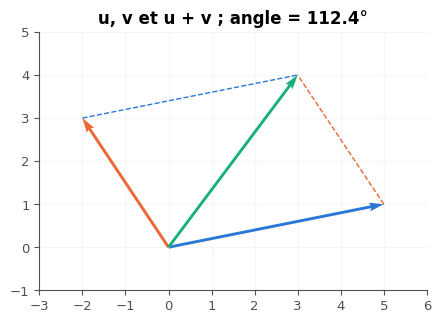

In [31]:
def draw_vectors(ax, u, v):
    """Draw u, v and u + v from the origin in ax (ax.quiver), with equal axes and the angle in the title."""
    s = (u[0] + v[0], u[1] + v[1])
    ax.quiver([0, 0, 0], [0, 0, 0], [u[0], v[0], s[0]], [u[1], v[1], s[1]], color=["C0", "C1", "C2"],
              angles="xy", scale_units="xy", scale=1)
    ax.plot([u[0], s[0]], [u[1], s[1]], "C1--", linewidth=1)
    ax.plot([v[0], s[0]], [v[1], s[1]], "C0--", linewidth=1)
    xs, ys = [0, u[0], v[0], s[0]], [0, u[1], v[1], s[1]]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 1, max(ys) + 1)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    dot = u[0] * v[0] + u[1] * v[1]
    cosine = dot / (math.hypot(*u) * math.hypot(*v))
    angle = math.degrees(math.acos(max(-1.0, min(1.0, cosine))))
    ax.set_title(f"u, v et u + v ; angle = {angle:.1f}°")


fig, ax = plt.subplots(figsize=(5, 5))
draw_vectors(ax, (5, 1), (-2, 3))
plt.show()

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [32]:
with checked("R9.21 vérifications"):
    problems = []
    for u, v, angle in [((5, 1), (-2, 3), "112.4"), ((-3, 2), (1, 4), "70.3")]:
        fig, ax = plt.subplots(figsize=(5, 5))
        try:
            created = drawn(draw_vectors, ax, u, v)
        finally:
            plt.close(fig)                                 # only the checks below are shown here
        if created:
            problems.append("ta fonction ouvre sa propre figure : dessine dans l'axe reçu (ax.quiver, …)")
            break
        arrows = set()
        quivers = [q for q in ax.collections if hasattr(q, "U") and hasattr(q, "V")]
        for q in quivers:
            for a, b in zip(np.ravel(q.U), np.ravel(q.V)):
                arrows.add((round(float(a), 6), round(float(b), 6)))
        wanted = {tuple(float(c) for c in u), tuple(float(c) for c in v),
                  tuple(float(a + b) for a, b in zip(u, v))}
        if not wanted <= arrows:
            problems.append("trois flèches avec ax.quiver, parties de l'origine : u, v et u + v")
        elif any(getattr(q, "angles", None) != "xy" or getattr(q, "scale_units", None) != "xy"
                 or getattr(q, "scale", None) != 1 for q in quivers):
            problems.append("les réglages angles=\"xy\", scale_units=\"xy\", scale=1 de ax.quiver, pour que chaque "
                            "flèche ait exactement la longueur de son vecteur")
        x0, x1 = sorted(ax.get_xlim())
        y0, y1 = sorted(ax.get_ylim())
        tips = [(0, 0), u, v, (u[0] + v[0], u[1] + v[1])]
        if not all(x0 <= px <= x1 and y0 <= py <= y1 for px, py in tips):
            problems.append("des limites qui laissent voir les trois flèches en entier (ax.set_xlim, ax.set_ylim)")
        if ax.get_aspect() not in (1, 1.0, "equal"):
            problems.append("la même unité sur les deux axes : ax.set_aspect(\"equal\")")
        title = ax.get_title().replace(",", ".")
        if angle not in title:
            problems.append("l'angle entre u et v dans le titre, en degrés, avec 1 décimale (calculé dans la "
                            "fonction)")
        if problems:
            break
    if problems:
        print("❌ Ex R9.21 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R9.21 : les trois flèches, la même unité sur les deux axes et l'angle dans le titre.")

✅ Ex R9.21 : les trois flèches, la même unité sur les deux axes et l'angle dans le titre.


💡 Sans `ax.set_aspect("equal")`, matplotlib étire les axes pour remplir la figure : une unité horizontale n'a plus la même longueur qu'une unité verticale, et les angles dessinés sont faux (un angle droit n'a plus l'air droit). Le calcul, lui, ne change pas : le titre donne toujours le bon angle.

### Ex R9.22 — Le cercle trigonométrique : cos et sin d'un angle qui tourne 🔬 ★★ ⏱️ 20 min
**Objectif :** explorer numériquement le cosinus et le sinus sur un tour complet : la relation cos² + sin² = 1, leurs comparaisons, leur maximum et la dérivée du sinus.  
**Prérequis :** fiche §6 ; workbookIA 0A §100.8.3 (calcul vectorisé) · **Parcours :** C

La cellule fournie définit `degrees`, 360 angles en degrés (0,5°, 1,5°, …, 359,5°), et `whole`, les angles entiers de 0° à 359°. Avec NumPy (`np.radians`, `np.cos`, `np.sin`, `np.max`, `np.abs`, `np.sum`, `np.argmax`) :
- a) `close_to_1` : vrai si, pour tous les angles de `degrees`, $\lvert \cos^2\theta + \sin^2\theta - 1 \rvert$ reste inférieur à $10^{-12}$ (un booléen) ;
- b) `first_sin_above` : le premier angle de `degrees`, en degrés, pour lequel $\sin\theta > \cos\theta$ (sur un tableau de booléens, `np.argmax` donne la position du premier `True`) ;
- c) `argmax_sin` : l'angle de `whole`, en degrés, pour lequel $\sin\theta$ est le plus grand ;
- d) `slope` : le taux d'accroissement $\frac{\sin(1 + h) - \sin 1}{h}$, avec $h = 10^{-5}$ (6 décimales), à comparer avec $\cos 1$.

Puis, dans la cellule qui suit la vérification, trace sur un même graphique $\cos$ et $\sin$ entre 0 et $4\pi$, avec une légende et l'abscisse en radians.

Dans ta copie : sur quels intervalles d'angles a-t-on $\cos\theta > \sin\theta$ ? Dessine-les sur le cercle. Que montre d) sur la dérivée de $\sin$ ?

In [33]:
degrees = np.arange(360) + 0.5          # 0.5°, 1.5°, ..., 359.5°: no angle where cos = sin exactly
whole = np.arange(360)                   # 0°, 1°, ..., 359°

In [34]:
theta = np.radians(degrees)
close_to_1 = bool(np.max(np.abs(np.cos(theta) ** 2 + np.sin(theta) ** 2 - 1)) < 1e-12)
first_sin_above = float(degrees[np.argmax(np.sin(theta) > np.cos(theta))])
argmax_sin = int(whole[np.argmax(np.sin(np.radians(whole)))])
h = 1e-5
slope = (math.sin(1 + h) - math.sin(1)) / h
print("a)", close_to_1, " b)", first_sin_above, " c)", argmax_sin, " d)", round(slope, 6), " cos 1 =", round(math.cos(1), 6))

a) True  b) 45.5  c) 90  d) 0.540298  cos 1 = 0.540302


In [35]:
wbm.record("R9.22a", True, mistakes={"compare la plus grande valeur de |cos² + sin² − 1| à 1e-12": False})
wbm.record("R9.22b", 45.5, decimals=1,
           mistakes={"np.sin et np.cos attendent des radians : convertis les degrés avec np.radians": 1.5,
                     "c'est la position dans le tableau ; l'angle est degrees[position]": 45,
                     "c'est le premier angle où cos θ > sin θ : relis le sens de la comparaison": 0.5})
wbm.record("R9.22c", 90, mistakes={"np.sin attend des radians : convertis les degrés avec np.radians": 322})
wbm.record("R9.22d", (math.sin(1 + 1e-5) - math.sin(1)) / 1e-5, decimals=6,
           mistakes={"le taux d'accroissement se divise par h": math.sin(1 + 1e-5) - math.sin(1),
                     "c'est cos 1 lui-même ; calcule le taux d'accroissement demandé, qui s'en approche": math.cos(1)})

WBM_ANSWER {"hash": "b3c0c9252cac9ed7678070dfbda36891d422cf9461bd78579038d3c0fd666092", "id": "R9.22a", "kind": "bool", "mistakes": {"9b632e43c4e56c49cd2fdb820cab1cb3abccb3c202f89e17d125402791b1a892": "compare la plus grande valeur de |cos² + sin² − 1| à 1e-12"}}
📝 Ex R9.22a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 1, "hash": "c489cdb2f88af0b8fd0970206af1da7b63d8328db32370166ed63fb4a13cbdb2", "hash_coarse": "ff39e6cb2c1bae1c20142e30d33c65541f365cc60f11cb5bbd065dfbbe99f10d", "id": "R9.22b", "kind": "float", "magnitude": 1, "mistakes": {"8802d0c6931ed75927bb45037c3287f94c50ee1c3c36de1f46ec6ac4e7a0a72f": "c'est la position dans le tableau ; l'angle est degrees[position]", "c69c1025a9fc9b108d0048e4093229a60671c2ec8b1fb7336bfb5080eeb30d9b": "np.sin et np.cos attendent des radians : convertis les degrés avec np.radians", "d3b427a3e7e5f9a7cee8d6a114ef02fbe07ef779673c69f6148d6c1509141eed": "c'est le premier angle où cos θ > sin θ : relis le sens de la comparaison"}, "sign": 1}
📝 E

**Le tracé** de $\cos$ et $\sin$ entre 0 et $4\pi$ (`np.linspace`, `ax.plot`, `ax.legend`).

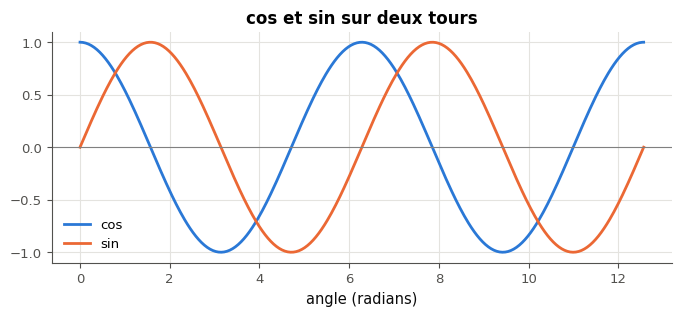

In [36]:
t = np.linspace(0, 4 * np.pi, 400)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, np.cos(t), label="cos")
ax.plot(t, np.sin(t), label="sin")
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set_xlabel("angle (radians)")
ax.legend()
ax.set_title("cos et sin sur deux tours")
plt.show()

💡 $\sin\theta$ dépasse $\cos\theta$ à partir de 45° (le premier angle de la grille est 45,5°), et jusqu'à 225° : $\cos\theta > \sin\theta$ pour $\theta$ entre $-135°$ et $45°$, la moitié du cercle. Le taux d'accroissement de d) vaut environ 0,540298, tout près de $\cos 1 \approx 0{,}540302$ : la pente de la courbe de $\sin$ en 1 est $\cos 1$, comme le dit $\sin' = \cos$ (en radians).

## Partie C · Radians, degrés et flottants

Fiche §5 et §6. Trois confusions entre degrés et radians à trouver, puis un test d'orthogonalité qui résiste aux arrondis.

### Ex R9.23 — Chasse à l'erreur : radians et degrés 🐛 ★ ⏱️ 15 min
**Objectif :** repérer les confusions entre degrés et radians dans du code, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §6 · **Parcours :** C, E

Voici cinq lignes de code, chacune avec ce qu'en attend son auteur. Trois sont fausses. **Sans exécuter d'abord**, trouve-les.

- **(A)** « Le sinus de 45° : `math.sin(45)`. »
- **(B)** « Le sinus de 45° : `math.sin(math.radians(45))`. »
- **(C)** « $\frac{\pi}{3}$ radian, converti en degrés : `(math.pi / 3) * 180 / math.pi`. »
- **(D)** « L'angle, en degrés, dont le cosinus vaut 0,5 : `math.acos(0.5)`. »
- **(E)** « 30° en radians : `30 * 180 / math.pi`. »

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des cinq lignes, de (A) à (E), la valeur exacte de ce que décrit la phrase de son auteur, calculée correctement (une liste de 5 nombres, 4 décimales).

Tu peux exécuter les lignes après avoir répondu, pour vérifier. Dans ta copie : pour chaque ligne fausse, quelle règle a été oubliée ?

In [37]:
answer_R9_23a = "ADE"
answer_R9_23b = [math.sin(math.radians(45)), math.sin(math.radians(45)), math.degrees(math.pi / 3),
                 math.degrees(math.acos(0.5)), math.radians(30)]
print(answer_R9_23a, [round(v, 4) for v in answer_R9_23b])
print("the five lines give:", math.sin(45), math.sin(math.radians(45)), (math.pi / 3) * 180 / math.pi,
      math.acos(0.5), 30 * 180 / math.pi)

ADE [0.7071, 0.7071, 60.0, 60.0, 0.5236]
the five lines give: 0.8509035245341184 0.7071067811865475 59.99999999999999 1.0471975511965979 1718.8733853924698


In [38]:
wbm.record("R9.23a", "ADE",
           mistakes={"il manque une ligne fautive : relis chaque appel à une fonction trigonométrique : reçoit-elle bien des radians ?": "DE",
                     "il manque une ligne fautive : relis chaque ligne qui annonce une valeur : dans quelle unité la fonction répond-elle ?": "AE",
                     "il manque une ligne fautive : relis chaque conversion : 180° doivent donner π": "AD",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABDE",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "ACDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque appel à une fonction trigonométrique : reçoit-elle bien des radians ?": "BDE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque appel à une fonction trigonométrique : reçoit-elle bien des radians ?": "CDE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque ligne qui annonce une valeur : dans quelle unité la fonction répond-elle ?": "ABE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque ligne qui annonce une valeur : dans quelle unité la fonction répond-elle ?": "ACE",
                     "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque conversion : 180° doivent donner π": "ABD",
                     "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque conversion : 180° doivent donner π": "ACD",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "D", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "C", "AB", "AC", "BC", "BD", "BE", "CD", "CE", "ABC", "BCD", "BCE", "ABCD", "ABCE", "BCDE"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE"}})
wbm.record("R9.23b", [math.sqrt(2) / 2, math.sqrt(2) / 2, 60.0, 60.0, math.pi / 6], decimals=4,
           mistakes={"ce sont les valeurs que calcule le code ; donne celles que décrit chaque phrase":
                         [math.sin(45), math.sqrt(2) / 2, 60.0, math.pi / 3, 30 * 180 / math.pi],
                     "la phrase de (D) demande l'angle en degrés": [math.sqrt(2) / 2, math.sqrt(2) / 2, 60.0,
                                                                   math.pi / 3, math.pi / 6]})

WBM_ANSWER {"hash": "4e62441c0510dc5be114b7b9c9d2b2d85637b69d075cd8c580be278802116955", "id": "R9.23a", "kind": "str", "mistakes": {"024c70393b5602493529b04674ce7bde0c23409a21ee87aaf4a427c12b952149": "la ligne (B) est correcte, et il manque une ligne fautive : relis chaque ligne qui annonce une valeur : dans quelle unité la fonction répond-elle ?", "0c82568702f05c6505e99ddc8c838accfcaf70349b466a32d86668602dee62cb": "il manque une ligne fautive : relis chaque appel à une fonction trigonométrique : reçoit-elle bien des radians ?", "186310d509ec236b25b29fb6b70432508215032c916facaeae17cf18ab9f0fe7": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "1db0ee10a8781dc8ba67b4065d781c6669894646d55359e9c7547fae662be968": "la ligne (C) est correcte, et il manque une ligne fautive : relis chaque ligne qui annonce une valeur : dans quelle unité la fonction répond-elle ?", "1f56ef727d89a8d6903370ed5e659353f0defca503d499ee213153e

💡 (A) `math.sin(45)` calcule le sinus de 45 radians, environ 0,851, au lieu de $\frac{\sqrt{2}}{2} \approx 0{,}7071$. (D) `math.acos` rend des radians : $\frac{\pi}{3} \approx 1{,}0472$, qui vaut bien 60°, mais pas le nombre 60 ; il fallait `math.degrees(math.acos(0.5))`. (E) La conversion est à l'envers : de degrés en radians, on multiplie par $\frac{\pi}{180}$, ce qui donne $\frac{\pi}{6} \approx 0{,}5236$. (B) et (C) sont justes.

### Ex R9.24 — Comparer deux flottants : `np.isclose` 🛠️ ★ ⏱️ 10 min
**Objectif :** tester l'orthogonalité de vecteurs à coordonnées décimales sans être trompé par les arrondis.  
**Prérequis :** fiche §5 ; R0 (les flottants) · **Parcours :** C

Sur papier, $\vec{u} = (0{,}1 ; 0{,}7)$ et $\vec{v} = (2{,}1 ; -0{,}3)$ sont orthogonaux : $0{,}21 - 0{,}21 = 0$. La cellule fournie calcule leur produit scalaire en flottants : il ne vaut pas exactement 0 (R0 : les flottants forment une grille). Un test `u·v == 0` se tromperait donc.

1. Écris `is_orthogonal(u, v, tol=1e-9)`, qui renvoie `True` quand le produit scalaire est nul **à `tol` près**, en valeur absolue. Deux outils font cette comparaison : `math.isclose(x, 0, abs_tol=tol)` et `np.isclose(x, 0, atol=tol)` (qui renvoie un booléen de NumPy : convertis-le avec `bool(...)`).
2. La cellule de vérification essaie ta fonction sur cinq cas.

Dans ta copie : que renvoie `math.isclose(1e-17, 0)`, sans `abs_tol` ? Pourquoi une tolérance **relative** (« à 1e-9 près de la valeur ») ne peut-elle pas servir pour comparer à 0 ?

In [39]:
u = (0.1, 0.7)
v = (2.1, -0.3)                          # 0.1 × 2.1 − 0.7 × 0.3 = 0.21 − 0.21 = 0: orthogonal on paper
print("u·v =", u[0] * v[0] + u[1] * v[1])

u·v = 2.7755575615628914e-17


In [40]:
def is_orthogonal(u, v, tol=1e-9):
    """True when u·v is 0 up to tol (in absolute value): a float dot product is rarely exactly 0."""
    dot = sum(a * b for a, b in zip(u, v))
    return math.isclose(dot, 0, abs_tol=tol)


print(is_orthogonal(u, v), u[0] * v[0] + u[1] * v[1] == 0, math.isclose(1e-17, 0), bool(np.isclose(1e-17, 0)))

True False False True


In [41]:
with checked("R9.24 vérifications"):
    problems = []
    result = is_orthogonal(u, v)
    if result is None:
        problems.append("is_orthogonal ne renvoie rien (None) : il manque un return (print affiche, mais ne renvoie "
                        "pas)")
    elif not isinstance(result, bool):
        kind = ("un booléen de NumPy (np.isclose en renvoie un)" if type(result).__module__ == "numpy"
                else f"un objet de type {type(result).__name__}")
        problems.append(f"is_orthogonal doit renvoyer un booléen de Python, True ou False, et non {kind} : "
                        "convertis avec bool(...)")
    elif result is not True:
        problems.append("is_orthogonal(u, v) doit être True : sur papier, u·v vaut 0")
    elif is_orthogonal((1, 2), (-3, 1)) is not False:
        problems.append("is_orthogonal((1, 2), (-3, 1)) doit être False : u·v vaut −1 ; compare sa valeur absolue "
                        "à tol")
    if not problems and is_orthogonal((1, 0), (1e-6, 1)) is not False:
        problems.append("is_orthogonal((1, 0), (1e-6, 1)) doit être False : 1e-6 dépasse la tolérance")
    if not problems and is_orthogonal((3, 4), (-4, 3)) is not True:
        problems.append("is_orthogonal((3, 4), (-4, 3)) doit être True")
    if not problems and is_orthogonal((2, 1), (1, 1), tol=10) is not True:
        problems.append("le paramètre tol doit être utilisé : avec tol=10, (2 ; 1) et (1 ; 1) passent")
    if problems:
        print("❌ Ex R9.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R9.24 : is_orthogonal tolère les arrondis des flottants, et seulement eux.")

✅ Ex R9.24 : is_orthogonal tolère les arrondis des flottants, et seulement eux.


💡 `math.isclose(1e-17, 0)` vaut `False` : sa tolérance par défaut est relative (`rel_tol=1e-9`, « à un milliardième de la plus grande des deux valeurs près »), et un milliardième de 0 vaut 0. Pour comparer à 0, il faut une tolérance absolue (`abs_tol`) ; `np.isclose` en a une par défaut (`atol=1e-8`).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu une distance, un vecteur, une norme et l'équation d'une droite ?
2. Sais-tu calculer un produit scalaire, reconnaître des vecteurs orthogonaux et en déduire un angle ?
3. Passes-tu des degrés aux radians, et lis-tu cos et sin sur le cercle trigonométrique ?

**La suite** : l'examen blanc CP0, le bilan de la remise à niveau. Puis, dans workbookIA, le chapitre 0B.